# Multi-Class Random Forest Classification

Uses optimal hyperparameters:
- n_estimators: 200
- min_samples_leaf: 1
- bag_fraction: 0.3
- max_depth (maxNodes): 10

In [1]:
import os
import ee
import geemap
from dotenv import load_dotenv
import seaborn as sns
import matplotlib.pyplot as plt

load_dotenv()
ee.Initialize(project=os.getenv('EE_PROJECT_ID'))



In [2]:
# Define Jabalpur boundary using FAO GAUL (2025)
jabalpur = ee.FeatureCollection('FAO/GAUL/2025/level2').filter(
    ee.Filter.And(
        ee.Filter.eq('GAUL2_NAME', 'Jabalpur'),
        ee.Filter.eq('GAUL0_NAME', 'India')
    )
).geometry()

def mask_s2_clouds(image):
    qa = image.select('QA60')
    cloud  = 1 << 10
    cirrus = 1 << 11
    mask = qa.bitwiseAnd(cloud).eq(0).And(qa.bitwiseAnd(cirrus).eq(0))
    return image.updateMask(mask).divide(10000)

dataset = (
    ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
      .filterDate('2025-03-01', '2025-04-30')
      .filterBounds(jabalpur)
      .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 15))
      .map(mask_s2_clouds)
)
composite = dataset.median().clip(jabalpur)

ndvi = composite.normalizedDifference(['B8', 'B4']).rename('NDVI')
ndwi = composite.normalizedDifference(['B3', 'B8']).rename('NDWI')
ndbi = composite.normalizedDifference(['B11', 'B8']).rename('NDBI')
savi = composite.expression(
    '1.5 * (NIR - RED) / (NIR + RED + 0.5)',
    {'NIR': composite.select('B8'), 'RED': composite.select('B4')}
).rename('SAVI')

composite = composite.addBands([ndvi, ndwi, ndbi, savi])
bands = ['B2', 'B3', 'B4', 'B8', 'B11', 'B12', 'NDVI', 'NDWI', 'NDBI', 'SAVI']


In [3]:
water = ee.FeatureCollection('projects/ai-project-513116/assets/water_points')
forest = ee.FeatureCollection('projects/ai-project-513116/assets/forest_points')
soil = ee.FeatureCollection('projects/ai-project-513116/assets/barren_points')
buildings = ee.FeatureCollection('projects/ai-project-513116/assets/urban_points')

class_names = ['Forest', 'Water', 'Buildings', 'Soil']

all_points = water.merge(forest).merge(soil).merge(buildings)

training = (
    composite.select(bands)
             .sampleRegions(
                 collection=all_points,
                 properties=['label'],
                 scale=10
             )
             .filter(ee.Filter.notNull(bands + ['label']))
             .randomColumn('random', 42)
)

train_set = training.filter(ee.Filter.lt('random', 0.7))
test_set = training.filter(ee.Filter.gte('random', 0.7))
print("Train Set Size:", train_set.size().getInfo())
print("Test Set Size:", test_set.size().getInfo())


Train Set Size: 2800
Test Set Size: 1200


Overall Accuracy: 0.9083333333333333
Kappa Coefficient: 0.877655319815482

--- Class-wise Accuracy ---
Forest: 0.9274
Water: 0.9891
Buildings: 0.8505
Soil: 0.8712



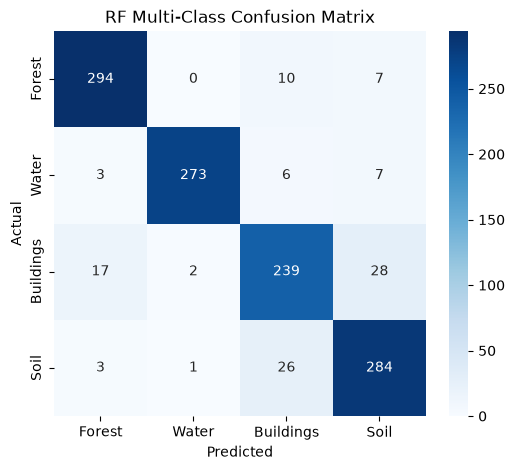

In [4]:
rf_classifier = ee.Classifier.smileRandomForest(
    numberOfTrees=200,
    minLeafPopulation=1,
    bagFraction=0.3,
    maxNodes=10
).train(
    features=train_set,
    classProperty='label',
    inputProperties=bands
)

test_classified = test_set.classify(rf_classifier)
confusion_matrix = test_classified.errorMatrix('label', 'classification')

print('Overall Accuracy:', confusion_matrix.accuracy().getInfo())
print('Kappa Coefficient:', confusion_matrix.kappa().getInfo())

print('\n--- Class-wise Accuracy ---')
consumers_acc = confusion_matrix.consumersAccuracy().getInfo()

for i, name in enumerate(class_names):
    # Safely access the 0th row, then the i-th column
    if i < len(consumers_acc[0]):
        acc = consumers_acc[0][i] if consumers_acc[0][i] is not None else 0.0
    else:
        acc = 0.0
        
    print(f'{name}: {acc:.4f}')

print()

cm_array = confusion_matrix.array().getInfo()

plt.figure(figsize=(6, 5))
sns.heatmap(cm_array, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('RF Multi-Class Confusion Matrix')
plt.show()

In [7]:
classified = composite.select(bands).classify(rf_classifier)
classified_smooth = classified.focalMode(radius=1, kernelType='square', units='pixels')

class_palette = ['00FF00', '0000FF', 'FF0000', 'D2B48C']

Map = geemap.Map(center=[23.234, 79.976], zoom=10)
Map.addLayer(composite, {'bands': ['B4', 'B3', 'B2'], 'min': 0, 'max': 0.3}, 'RGB Composite')
Map.addLayer(classified_smooth, {'min': 0, 'max': 3, 'palette': class_palette}, 'RF Classification')

legend_dict = {
    'Forest (0)':     '00FF00',
    'Water (1)':      '0000FF',
    'Buildings (2)':  'FF0000',
    'Soil (3)':       'D2B48C'
}
Map.add_legend(title='Land Cover', legend_dict=legend_dict)
Map.addLayer(jabalpur, {}, 'Jabalpur Boundary')
Map


Map(center=[23.234, 79.976], controls=(WidgetControl(options=['position', 'transparent_bg'], position='toprigh…

In [6]:
area_image = ee.Image.pixelArea().addBands(classified_smooth)
areas = area_image.reduceRegion(
    reducer=ee.Reducer.sum().group(groupField=1, groupName='class'),
    geometry=jabalpur,
    scale=30,
    maxPixels=1e10
)

area_data = areas.getInfo()['groups']
print("--- Class Areas for Jabalpur (Hectares) ---")
for entry in area_data:
    ha = entry['sum'] / 10000
    print(f"{class_names[entry['class']]}: {ha:.2f} ha")


--- Class Areas for Jabalpur (Hectares) ---
Forest: 232006.25 ha
Water: 20146.98 ha
Buildings: 158292.89 ha
Soil: 98815.12 ha
